## Dorado Spillway-Release Workflow (Unstructured Delft3DFM)

This notebook releases particles from the **Bonnet Carré Spillway (BCS)** and
tracks them across Lake Pontchartrain to see where the diverted water goes and
how long it stays. It is the single-source version of the workflow; if you want
to release from several places at once (spillway plus tributaries, etc.), use
`DORADO-04-multisource_release_workflow.ipynb` instead.

**What it does, start to finish:**

1. Load the gridded (unstructured) Delft3D-FM flow field, either from a saved
   file or by building one from `FlowFM_map.nc`.
2. Load a **daily particle-release schedule** (a CSV made by
   `DORADO-03a-create_spillway_particles_selected_years.ipynb`) that says how
   many particles to drop each day.
3. Spread each day's particles across the model timesteps.
4. Release the particles from a fixed line at the spillway and run the `dorado`
   random-walk routing.
5. Compute **exposure time** and save the `walk_data` and results.

**You need before running:**
- A spillway particle CSV in `outputs/dorado/from_spillway/` (from `DORADO-03a`).
- Either a saved unstructured grid file, or the model's `FlowFM_map.nc` if you
  set `unstructured_mode = "build"`.
</VSCode.Cell>


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import json
import sys
import time as tm
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
from matplotlib import pyplot as plt
from pyproj import Proj

import dorado

import dorado.particle_track as ptfrom src.dorado_utils import daily_to_steps

    sys.path.insert(0, str(_PROJECT_ROOT))

# Make src/ importable and pull in shared DORADO helpersif str(_PROJECT_ROOT) not in sys.path:
_PROJECT_ROOT = Path.cwd().parent

### 1. Configure Paths and Runtime Settings

Set the `model_run` name (it is reused for every load/save so everything points
at the same scenario) and choose how to get the gridded flow field:

- `unstructured_mode = "load"` — read an unstructured grid file you already made
  (fast, the usual choice).
- `unstructured_mode = "build"` — create it from `FlowFM_map.nc` and save it to
  disk. Only needed the first time for a new model run. This branch is the only
  place the hardcoded `data_folder` path to the raw model output is used, so
  update that path if you build.
</VSCode.Cell>


In [2]:
PROJECT_ROOT = Path.cwd().parent
NOTEBOOK_DATA = PROJECT_ROOT / "notebooks" / "data"

# Core run identifier shared across the notebook
model_run = "diversion_2013_01"

# Choose how to populate `unstructured`:
# - "load": read an existing JSON created previously
# - "build": create from FlowFM_map.nc and save to disk
unstructured_mode = "load"  # options: "load" or "build"

unstructured_data_location = (PROJECT_ROOT / "outputs" / "dorado" / model_run / f"unstructured_model_Delft3DFM_{model_run}.txt")

# Only used when unstructured_mode == "build"
data_folder = Path(r"C:\Users\hydro\BCS_Paper\WL_Lake_Pontchartrain_Model_2013.dsproj_data\FlowFM\output")

if unstructured_mode == "build":
    with xr.open_dataset(data_folder / "FlowFM_map.nc") as map_xr:
        x = map_xr["mesh2d_face_x"].values.astype(np.float32).tolist()
        y = map_xr["mesh2d_face_y"].values.astype(np.float32).tolist()
        elevation = map_xr["mesh2d_flowelem_bl"].values.astype(np.float32).tolist()
        time = map_xr["time"].values.astype(np.float32).tolist()

        unstructured = {
            "time": time[1:],
            "elevation": elevation,
            "x_face": x,
            "y_face": y,
            "timesteps": [],
        }

        for i in range(len(time) - 1):
            stage = map_xr["mesh2d_s1"].isel(time=1 + i).values.astype(np.float32)
            depth = map_xr["mesh2d_waterdepth"].isel(time=1 + i).values.astype(np.float32)
            u = map_xr["mesh2d_ucx"].isel(time=1 + i).values.astype(np.float32)
            v = map_xr["mesh2d_ucy"].isel(time=1 + i).values.astype(np.float32)
            unstructured["timesteps"].append([stage.tolist(), depth.tolist(), u.tolist(), v.tolist()])

    unstructured_data_location.parent.mkdir(parents=True, exist_ok=True)
    with open(unstructured_data_location, "w") as f:
        json.dump(unstructured, f)

elif unstructured_mode == "load":
    with open(unstructured_data_location, "r") as f:
        unstructured = json.load(f)

print("Unstructured mode:", unstructured_mode)
print("Unstructured source:", unstructured_data_location)

Unstructured mode: load
Unstructured source: c:\Users\hydro\Lake_Pontchartrain_Model\outputs\dorado\diversion_2013_01\unstructured_model_Delft3DFM_diversion_2013_01.txt


In [3]:
# Runtime settings for this scenario
hydrodt = 24  # timestep (hours)

particles_path = PROJECT_ROOT / "outputs" / "dorado" / "from_spillway" / "bcs_2013_particles.csv"
boundaries_path = NOTEBOOK_DATA / "boundaries_latlon.xlsx"

path2folder = PROJECT_ROOT / "outputs" / "dorado" / "from_spillway" / model_run
(path2folder / "figs").mkdir(parents=True, exist_ok=True)

boundaries = pd.read_excel(boundaries_path)

print("Model run:", model_run)
print("Particles file:", particles_path)

Model run: diversion_2013_01
Particles file: c:\Users\hydro\Lake_Pontchartrain_Model\outputs\dorado\from_spillway\bcs_2013_particles.csv


### 2. Load the Spillway Particle Schedule

Read the daily particle CSV (made by `DORADO-03a`). The helper below floors the
dates to whole days, treats any non-numeric counts as zero, and finds the first
day with a positive count — that day is when the release starts. If there are no
positive days, it stops with an error so you don't run an empty release.
</VSCode.Cell>


In [4]:
def load_particle_schedule(csv_path, date_col="datetime", value_col="particle_number"):
    particle_schedule = pd.read_csv(csv_path).copy()
    particle_schedule[date_col] = pd.to_datetime(particle_schedule[date_col])
    particle_schedule[value_col] = pd.to_numeric(
        particle_schedule[value_col], errors="coerce"
    ).fillna(0)
    particle_schedule = particle_schedule.sort_values(date_col).reset_index(drop=True)
    open_mask = particle_schedule[value_col] > 0
    particles_start_date = particle_schedule.loc[open_mask, date_col].min() if open_mask.any() else pd.NaT
    return particle_schedule, particles_start_date


DATE_COL = "datetime"
VAL_COL = "particle_number"
particle_schedule, particles_start_date = load_particle_schedule(
    particles_path, date_col=DATE_COL, value_col=VAL_COL)

if pd.isna(particles_start_date):
    raise ValueError("No positive particle release days found in particles CSV.")

print("Loaded particles file:", particles_path)
print("Particles start date:", particles_start_date.strftime("%Y-%m-%d"))

Loaded particles file: c:\Users\hydro\Lake_Pontchartrain_Model\outputs\dorado\from_spillway\bcs_2013_particles.csv
Particles start date: 2013-04-28


### 3. Build Particle-Release Schedule

Turn the daily particle totals into a per-timestep release count.

- `steps_per_day` comes from `hydrodt` (the model timestep in hours).
- The schedule is trimmed to the open window (first to last positive day) and
  reindexed to a continuous daily range. `fill_missing_days` decides what to do
  with gaps inside that window: `'interpolate'` fills them smoothly, `'zero'`
  treats them as no release.
- `daily_to_steps()` (from `src/dorado_utils.py`) then spreads each day's total
  evenly across that day's timesteps, so the same total goes out whether the
  model steps once or many times per day.

The plot at the bottom is a quick check that the daily release looks right.
</VSCode.Cell>


Particle mode: CSV-driven
Missing-day fill: interpolate
Total particles: 719


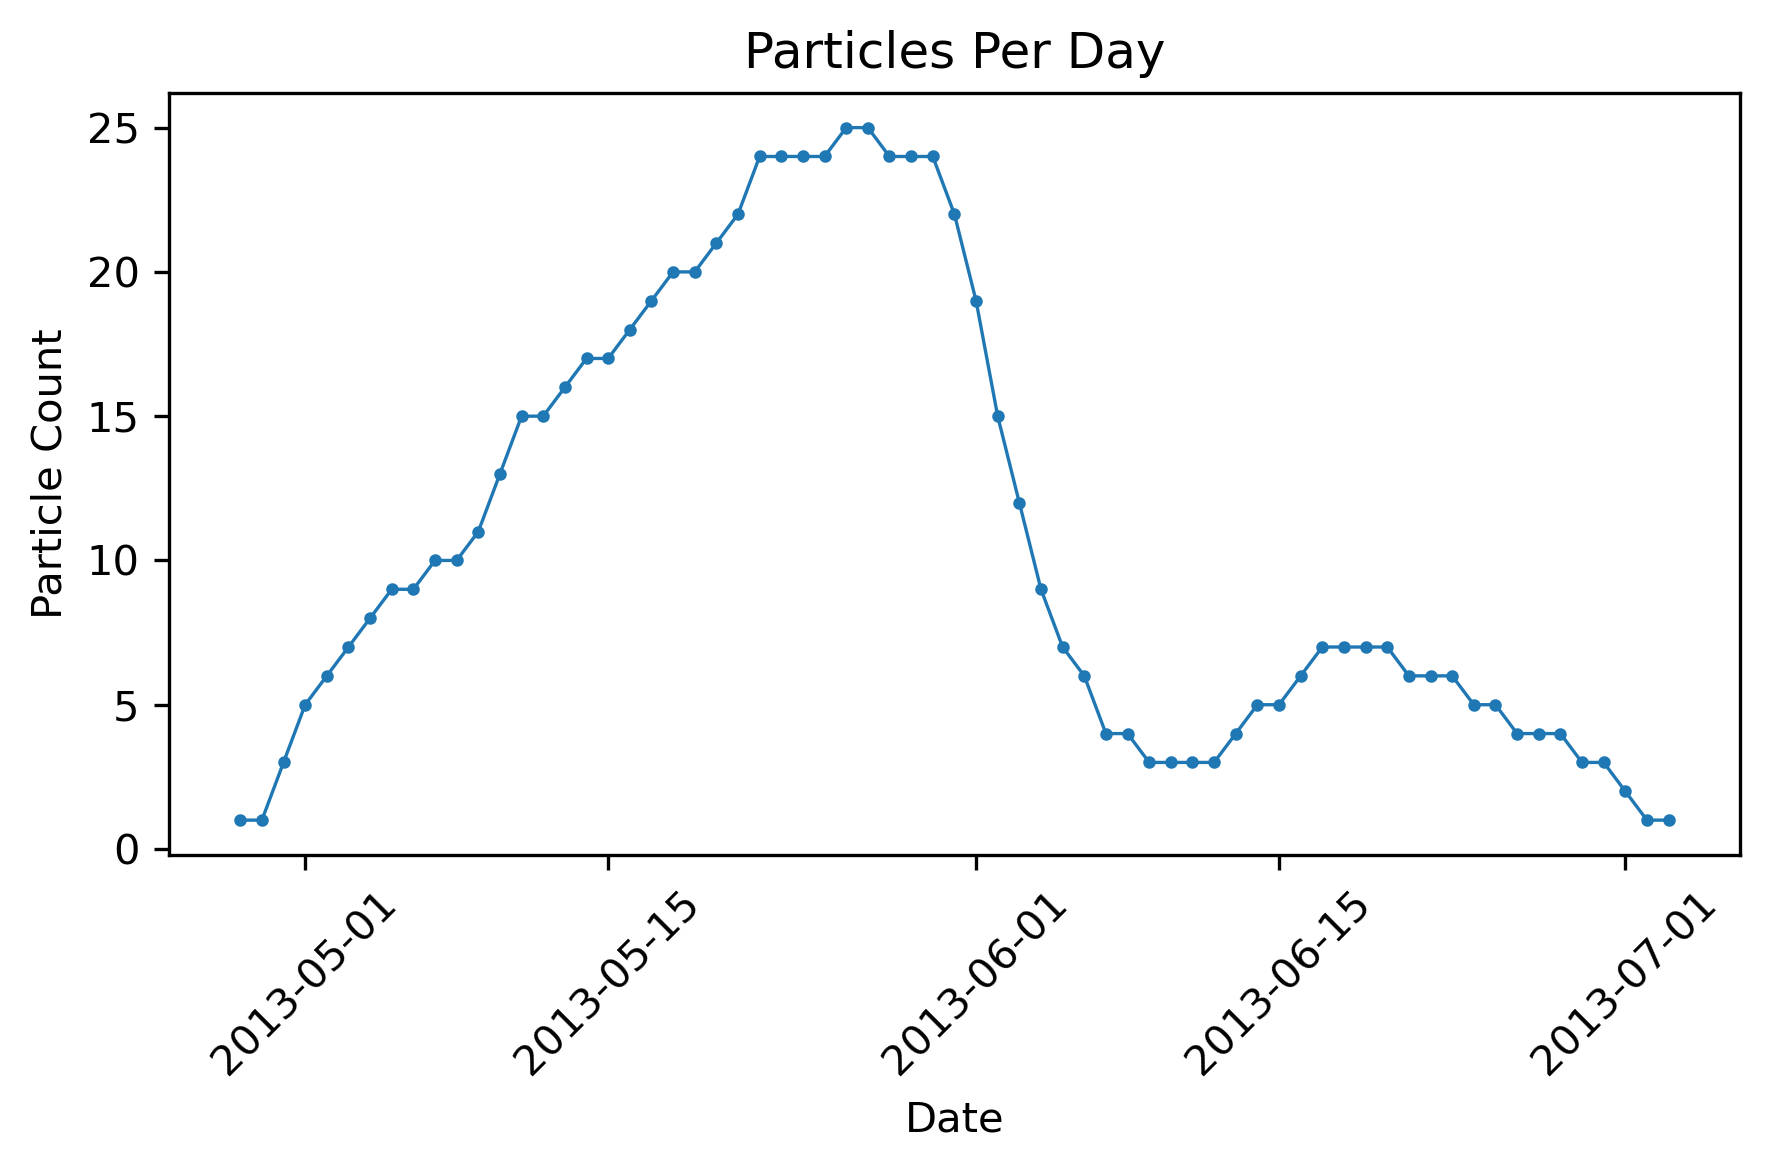

In [ ]:
steps_per_day = int(round(24 / hydrodt))
if steps_per_day <= 0:
    raise ValueError('hydrodt must produce at least one step per day.')

if 'particle_schedule' not in globals():
    raise RuntimeError('Run the particles loading cell first.')

fill_missing_days = 'interpolate'  # options: 'interpolate' or 'zero'

daily = particle_schedule.copy()
daily[DATE_COL] = pd.to_datetime(daily[DATE_COL]).dt.floor('D')
daily[VAL_COL] = pd.to_numeric(daily[VAL_COL], errors='coerce').fillna(0.0)
daily = daily.groupby(DATE_COL, as_index=False)[VAL_COL].sum().sort_values(DATE_COL)

thr = 0
open_mask = daily[VAL_COL] > thr
if not open_mask.any():
    raise ValueError('No spillway-open days found (all daily totals <= threshold).')

start_date = daily.loc[open_mask, DATE_COL].min()
end_date = daily.loc[open_mask, DATE_COL].max()

daily = (daily.set_index(DATE_COL)
            .reindex(pd.date_range(start_date, end_date, freq='D'))
            .rename_axis(DATE_COL))

if fill_missing_days == 'interpolate':
    daily[VAL_COL] = daily[VAL_COL].interpolate(method='time', limit_direction='both')
elif fill_missing_days == 'zero':
    daily[VAL_COL] = daily[VAL_COL].fillna(0)
else:
    raise ValueError("fill_missing_days must be 'interpolate' or 'zero'.")

daily[VAL_COL] = daily[VAL_COL].fillna(0).clip(lower=0)
daily = daily.reset_index()

daily_totals = np.round(daily[VAL_COL].to_numpy()).astype(int)

# Spread each day's particle total across the steps within that day
# (shared helper in src/dorado_utils.py).
particles = daily_to_steps(daily_totals, steps_per_day)
print('Particle mode: CSV-driven')
print('Missing-day fill:', fill_missing_days)
print('Total particles:', int(particles.sum()))

plt.figure(figsize=(6, 4), dpi=300)
plt.plot(daily[DATE_COL], daily_totals, marker='o', markersize=2, linewidth=0.8)
plt.title('Particles Per Day')
plt.xlabel('Date')
plt.ylabel('Particle Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 4. Project Coordinates, Grid Data, and Load Cell Types

Put the flow field onto a regular grid that `dorado` can walk particles across:

- Convert the unstructured grid and land boundaries from lat/lon into **UTM zone
  15** (meters), so distances are real.
- `pt.unstruct2grid()` interpolates the scattered face values onto a regular
  `resolution`-meter grid (100 m here) and returns an `elevation` array plus an
  interpolator (`myInterp`) used later for every timestep.
- One spot along the ocean boundary gets cut during gridding, so those cells are
  patched by interpolation (`interpolate_indices`). These indices are specific to
  this grid — leave them as-is unless you change the grid or resolution.

The depth plot is a sanity check that the gridded domain looks like the lake.
</VSCode.Cell>


731373.01 838696.8 3308499.64 3365342.66
13805


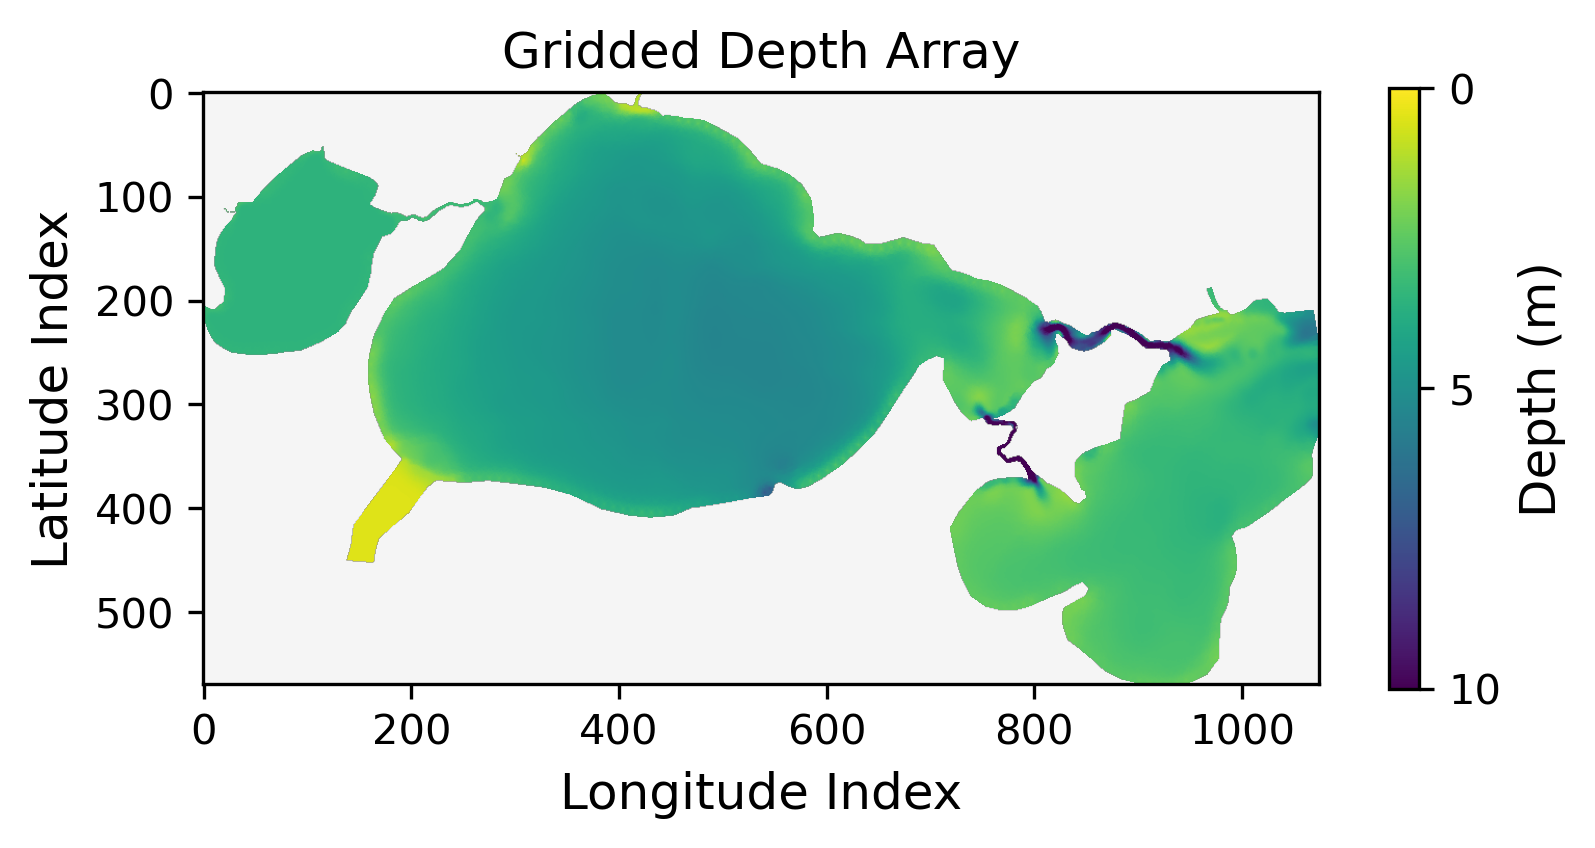

In [6]:
# Define UTM Zone
utm_proj = Proj(proj='utm', zone=15, ellps='WGS84')

# Convert Unstructured Grid lon (unstructured['x_face']) and lat (unstructured['y_face']) to UTM
(unstructured['x'], unstructured['y']) = utm_proj(unstructured['x_face'], unstructured['y_face'])
unstructured['x'], unstructured['y'] = np.round(unstructured['x'], 2), np.round(unstructured['y'],2)

# Convert land boundaries lon (boundaries['x']) and lat (boundaries['y']) to UTM
boundaries['x'], boundaries['y'] = utm_proj(boundaries['x'], boundaries['y'])

# Use list comprehension to convert into tuples
coordinates = [(round(float(x), 2), round(float(y), 2))for x, y in zip(unstructured['x'], unstructured['y'])]

# Let's see the extent of our domain
print(min(unstructured['x']), max(unstructured['x']), 
      min(unstructured['y']), max(unstructured['y']))
# As well as our number of data points
print(len(unstructured['x']))


resolution = 100 # meters (This is what I have set up for this model, see define particle locations below to see what to do if you want to change the model resolution, as you will need to create some files.)
knn = 5 # nearest neighbors used
myInterp, elevation = pt.unstruct2grid(coordinates, unstructured['elevation'], resolution, knn, boundary=boundaries, crop=True)

# Set ocean boundary and fix area that was cut
interpolate_indices = (320, 324, 779, 782)
elevation[interpolate_indices[0]:interpolate_indices[1], interpolate_indices[2]:interpolate_indices[3]] = pd.DataFrame(elevation[interpolate_indices[0]:interpolate_indices[1], interpolate_indices[2]:interpolate_indices[3]]).interpolate().values


# Let's plot the resulting grid to see what the output looks like:
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
cax = ax.imshow(elevation, vmin=-10, vmax=0)
cbar = fig.colorbar(cax, ax=ax, label='Depth (m)',shrink = 0.65)
ax.set_xlabel('Longitude Index', fontsize=12)
ax.set_ylabel('Latitude Index', fontsize=12)
cbar.ax.set_ylabel('Depth (m)', fontsize=12)
cbar.set_ticks([0, -5, -10])
cbar.set_ticklabels(['0', '5', '10'])
ax.set_facecolor('whitesmoke')
plt.title('Gridded Depth Array')
plt.show()


### 5. Define Seed Regions and Initial Release Location

Set two things:

- **`regions`** — the area of interest (the lake), read from the cell-type CSVs.
  Exposure time is measured against this mask (1 = count it, 0 = ignore).
- **`seed_xloc` / `seed_yloc`** — the grid cells where particles are released. By
  default this is a short line across the spillway. To release somewhere else,
  change these index ranges (rows/columns) and re-run.

The red dots on the plot show exactly where particles will start, so you can
confirm the release line is sitting on the spillway.
</VSCode.Cell>


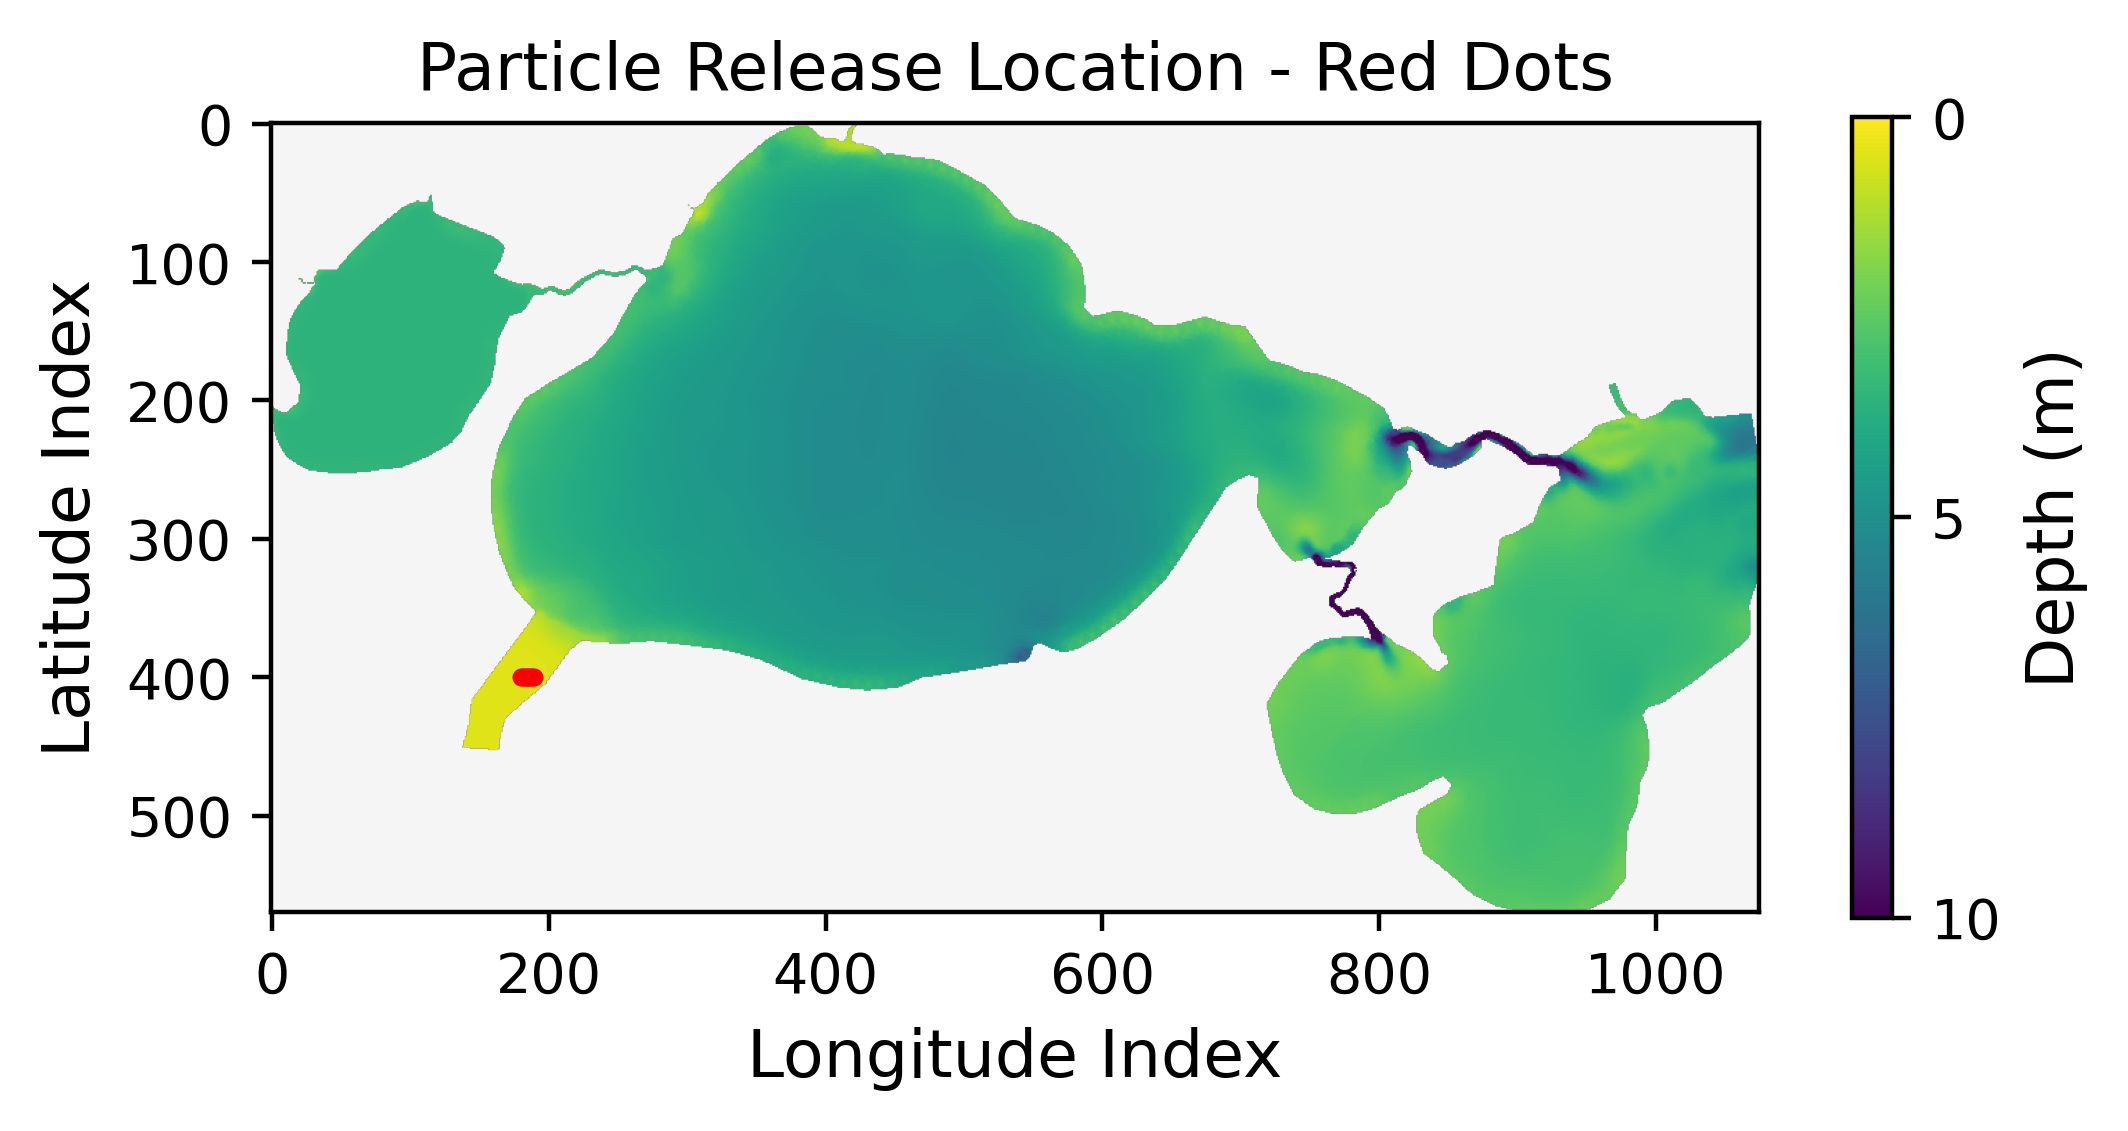

In [7]:

notebooks_data = PROJECT_ROOT / "notebooks" / "data"

# Base grid cell classification and isolated-LP mask
celltype_initial = np.genfromtxt(notebooks_data / "cell_type_all_100m.csv", delimiter=",")
celltype = np.genfromtxt(notebooks_data / "cell_type_all_100m_roi.csv", delimiter=",")

regions = np.zeros_like(elevation, dtype='int')

# Find all seed locations where celltype_roi == 1
seed_locations = np.argwhere(celltype == 1) 
regions[celltype == 1] = 1


# Example fixed release line (adjust as needed)
seed_yloc = list(range(180, 190))
seed_xloc = [400] * len(seed_yloc)

# Let's plot the resulting grid to see what the output looks like:
fig, ax = plt.subplots(figsize=(6, 4), dpi=400)
plt.scatter(seed_yloc, seed_xloc, c='r', s=5)
cax = ax.imshow(elevation, vmin=-10, vmax=0)
cbar = fig.colorbar(cax, ax=ax, label='Depth (m)',shrink = 0.65)
ax.set_xlabel('Longitude Index', fontsize=12)
ax.set_ylabel('Latitude Index', fontsize=12)
cbar.ax.set_ylabel('Depth (m)', fontsize=12)
cbar.set_ticks([0, -5, -10])
cbar.set_ticklabels(['0', '5', '10'])
ax.set_facecolor('whitesmoke')
plt.title('Particle Release Location - Red Dots')
plt.show()

#### Timestep Setup

Line the particle run up with the model clock and set the routing parameters:

- `startRange` is the hour-of-year of the first release, so particles start when
  the spillway actually opens (not at the start of the model).
- The run goes from that first release to the end of the model window;
  `timesteps_to_run` is how many `hydrodt`-sized steps that takes.
- `target_times` are the cumulative seconds at each step, used to time-stamp
  particle positions.
- `params` holds the `dorado` random-walk settings: `theta = 1.0` (water),
  `gamma`, `diff_coeff`, the grid spacing `dx`, and the dry-cell cutoff.
</VSCode.Cell>


In [8]:
## Set Times
release_dt = pd.Timestamp(particles_start_date)
year_start = pd.Timestamp(year=release_dt.year, month=1, day=1)
startRange = int((release_dt - year_start) / pd.Timedelta(hours=1))  # Hour-of-year index for first release
if startRange < 0 or startRange >= len(unstructured['time']):
    raise ValueError(f"Computed startRange={startRange} is outside model time range [0, {len(unstructured['time']) - 1}].")

endRange = len(unstructured['time']) - 1                    # End of available model time
timesteps = (endRange - startRange) // hydrodt              # Steps from first release to end of year/model time
model_timestep = 3600 * hydrodt                             # Timesteps between data in seconds

# Run through the end of model year/time from the first release (user-requested behavior).
timesteps_to_run = timesteps

# Ensure particles has one value per model step (pad with zeros if CSV schedule is shorter).
if len(particles) < timesteps_to_run:
    particles = np.pad(particles, (0, timesteps_to_run - len(particles)), mode='constant')

target_times = np.arange(0, model_timestep * (timesteps_to_run + 1), model_timestep)
target_times = [int(t) for t in target_times]
prev_counts = None

params = pt.modelParams()
params.theta = 1.0
params.gamma = 0.05
params.diff_coeff = 0.8
params.cell_type = np.where(np.isnan(elevation), 2, celltype_initial)
params.dx = resolution
params.dry_depth = 0.01
params.verbose = False

print('Particle release start:', release_dt)
print('Start range (hour-of-year):', startRange)
print('Run hydrodt (hours):', hydrodt)
print('Hours remaining in model window:', endRange - startRange)
print('Actual timesteps run:', timesteps_to_run)

Particle release start: 2013-04-28 00:00:00
Start range (hour-of-year): 2808
Run hydrodt (hours): 24
Hours remaining in model window: 5927
Actual timesteps run: 246


### 6. Run Dorado Iterations

Step through the model in time and move the particles. Each step:

1. Pull that timestep's stage, depth, and velocity onto the grid (with the same
   boundary patch as before) and hand them to `params`.
2. Release that step's new particles from the spillway line and run one routing
   iteration, carrying forward all the particles already in the water
   (`previous_walk_data`).
3. Record a travel time for every new particle position.

At the very last step, particles that are still in the domain get their final
time set to `NaN` — they are **right-censored**, so the exposure-time stats don't
pretend they left when they simply hadn't yet. Every so often the loop saves a
snapshot figure of where the particles are, which is handy for spotting problems
mid-run.

> This is the slow cell — a full spillway run can take a while.
</VSCode.Cell>


In [ ]:
for i in range(timesteps_to_run):
    tti = startRange + i * hydrodt

    stage = myInterp(unstructured['timesteps'][tti][0])
    depth = myInterp(unstructured['timesteps'][tti][1])
    u = myInterp(unstructured['timesteps'][tti][2])
    v = myInterp(unstructured['timesteps'][tti][3])

    for arr in [stage, depth, u, v]:
        sub = arr[interpolate_indices[0]:interpolate_indices[1], interpolate_indices[2]:interpolate_indices[3]]
        arr[interpolate_indices[0]:interpolate_indices[1], interpolate_indices[2]:interpolate_indices[3]] = pd.DataFrame(sub).interpolate().values

    params.topography = elevation
    params.stage = stage
    params.qx = u * depth
    params.qy = v * depth
    params.u = u
    params.v = v

    particle = pt.Particles(params)
    if i == 0:
        particle.generate_particles(int(particles[i]), seed_xloc, seed_yloc, seed_time=0, method='exact')
    else:
        particle.generate_particles(int(particles[i]), seed_xloc, seed_yloc, seed_time=float(target_times[i]), method='exact', previous_walk_data=walk_data)

    walk_data = particle.run_iteration(target_times[i])
    xi, yi, ti = dorado.routines.get_state(walk_data)

    x_key = 'xinds' if 'xinds' in walk_data else 'x_inds'
    t_key = 'travel_times'
    x_lists = walk_data[x_key]
    t_lists = walk_data.get(t_key, [[] for _ in x_lists])
    walk_data[t_key] = t_lists

    if prev_counts is None or len(prev_counts) != len(x_lists):
        prev_counts = [0] * len(x_lists)

    t_start = target_times[i - 1] if i > 0 else 0
    t_end = target_times[i]

    for p, x_list in enumerate(x_lists):
        cur_len = len(x_list)
        added = cur_len - prev_counts[p]
        if added <= 0:
            continue
        seg = [target_times[i]] * added
        if len(t_lists[p]) < cur_len:
            t_lists[p].extend([None] * (cur_len - len(t_lists[p])))
        t_lists[p][prev_counts[p]:cur_len] = seg
        prev_counts[p] = cur_len

    # Particles that are still present at the last timestep are right-censored:
    # use np.nan so downstream exposure ignores their terminal time instead of
    # treating them as having exited the system.
    if i == timesteps_to_run - 1:
        final_len = max(len(x_list) for x_list in x_lists)
        for p, x_list in enumerate(x_lists):
            if len(x_list) == final_len and t_lists[p]:
                t_lists[p][-1] = np.nan

    if i % 24 == 0 or i == timesteps_to_run - 1:
        fig, ax = plt.subplots(figsize=(6, 4), dpi=200)
        ax.scatter(yi, xi, c='firebrick', s=1)
        im = ax.imshow(particle.depth * -1, vmin=0, vmax=-25)
        plt.imshow(regions, cmap='bone', alpha=0.3)
        plt.title(f'Time: {int((target_times[i] / 3600) // 24)} Days Since Release')
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('Depth (m)')
        ax.set_facecolor('whitesmoke')
        plt.savefig(path2folder / f'output_by_dt{i}.png')
        plt.close()


### 7. Exposure Time and Save Outputs

Wrap up the run:

- Convert the particle grid indices back into UTM coordinates (`ind2coord`) so
  positions can be mapped later.
- Compute **exposure time** against the `regions` mask and plot the exposure-time
  distribution (with thresholds).
- Save the results to `outputs/dorado/from_spillway/<model_run>/`:
  - `<model_run>_WalkData.txt` — the full particle history (`walk_data`), reused
    by `DORADO-04-from_source_exposuretime.ipynb`.
  - `<model_run>_Exposure.npz` — exposure times plus the rasterized `elevation`,
    `celltype`, and the model timestep.
</VSCode.Cell>


100%|##########| 719/719 [00:01<00:00, 372.24it/s]


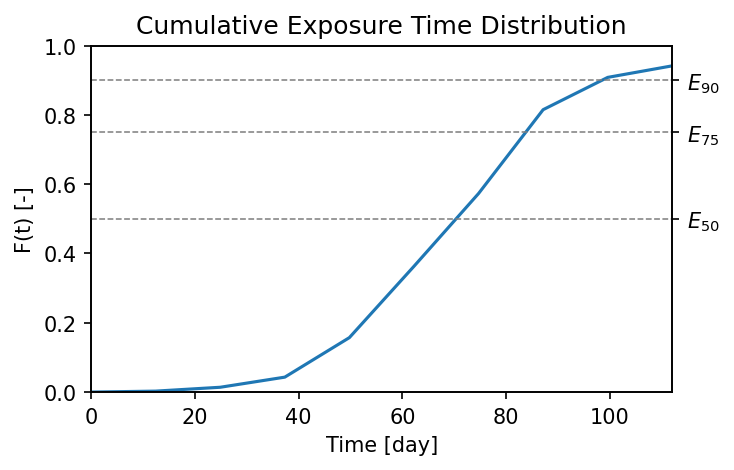

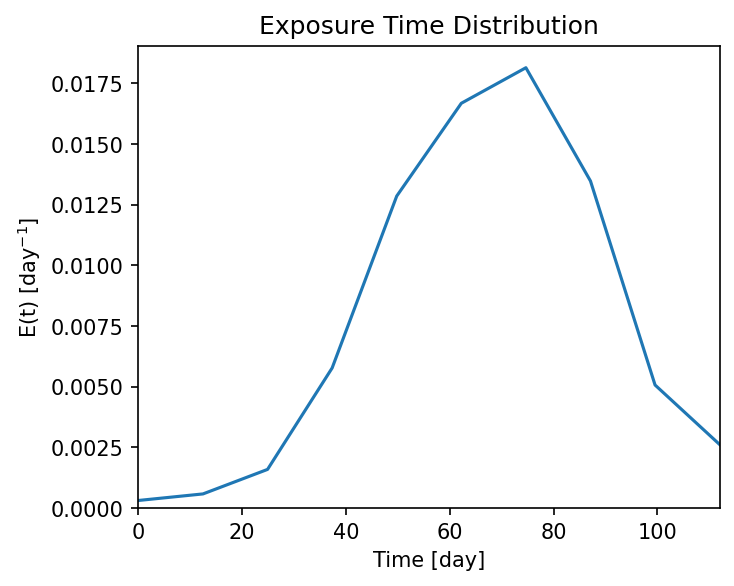

In [10]:
# Convert particle location indices back into UTM coordinates
walk_data = pt.ind2coord(walk_data, 
                         (min(unstructured['x']), 
                          min(unstructured['y'])), 
                         np.shape(elevation), resolution)

plot_dir = path2folder / 'figs'
plot_dir.mkdir(parents=True, exist_ok=True)

exposure_times = pt.exposure_time(walk_data, regions)

dorado.routines.plot_exposure_time(
    walk_data,
    exposure_times,
    str(path2folder),
    timedelta=model_timestep,
    nbins=10,
    uniform_timesteps=False,
    show_thresholds=True,
 )


json.dump(walk_data, open(path2folder / f'{model_run}_WalkData.txt', 'w'))
np.savez_compressed(
    path2folder / f'{model_run}_Exposure.npz',
    exposure_times=exposure_times,
    elevation=elevation,
    celltype=celltype,
    model_timestep=model_timestep
)

